# Why Softmax?

Softmax turns any vector of real-valued scores into a probability distribution:

$$\text{softmax}(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

It sits at the heart of attention (*Attention Is All You Need*, Eq. 1), classification heads, and LLM sampling. This notebook shows, one small demo at a time, the properties that make it so useful, and the one weakness that explains why attention divides by √d_k.

In [1]:
import math
import torch
import matplotlib.pyplot as plt

_ = torch.manual_seed(0)

### 1. Positive, sums to 1
Exponentiating makes every score positive; dividing by the total makes them sum to 1. Any scores in, a valid distribution out.

In [2]:
z = torch.tensor([2.0, 1.0, 0.1])
p = torch.softmax(z, dim=-1)
print("scores: ", z)
print("softmax:", p.round(decimals=3))
print("sum:    ", round(p.sum().item(), 6))  # float32 gives 1.0000001; rounding hides the tiny float error

scores:  tensor([2.0000, 1.0000, 0.1000])
softmax: tensor([0.6590, 0.2420, 0.0990])
sum:     1.0


### 2. A *soft* argmax
Order is preserved: the largest score always gets the largest weight. But unlike argmax, every option keeps some weight.

In [3]:
print("argmax: ", torch.nn.functional.one_hot(z.argmax(), 3))
print("softmax:", p.round(decimals=3))

argmax:  tensor([1, 0, 0])
softmax: tensor([0.6590, 0.2420, 0.0990])


**Why "soft" matters.** To learn, a model needs to know how a small change in a score changes the output.

With argmax, a small nudge changes nothing. The output only jumps when one score overtakes another. So there's nothing to learn from.

With softmax, any nudge moves all the outputs a little. That gives training a direction to move in, for every score.

Example: Consider a teacher who only gives you a Yes/No answer to a question. Then consider another teacher who tells you - You are wrong, but less wrong than before. You are right, but you are getting less right. The second teacher can help you learn better.

Below, we nudge one score and compare.

In [4]:
eps = 0.01
z_nudged = z + torch.tensor([0.0, eps, 0.0])   # nudge the second score

print("argmax change: ", (torch.nn.functional.one_hot(z_nudged.argmax(), 3)
                          - torch.nn.functional.one_hot(z.argmax(), 3)))
print("softmax change:", (torch.softmax(z_nudged, -1) - p).round(decimals=4))

J = torch.autograd.functional.jacobian(lambda s: torch.softmax(s, -1), z)
print("How each output moves when each score is nudged (rows: outputs, columns: scores):")
print(J.round(decimals=3))

argmax change:  tensor([0, 0, 0])
softmax change: tensor([-0.0016,  0.0018, -0.0002])
How each output moves when each score is nudged (rows: outputs, columns: scores):
tensor([[ 0.2250, -0.1600, -0.0650],
        [-0.1600,  0.1840, -0.0240],
        [-0.0650, -0.0240,  0.0890]])


**Reading the table.** Row = an output, column = the score we nudged.

- **The diagonal is positive.** Raise a score, and its own probability goes up.
- **Everything else is negative.** Raise one score, and all the other probabilities go down a little.
- **Every row and column adds up to 0.** The probabilities always sum to 1, so it's a zero-sum game: whatever one option gains, the others lose. Softmax never creates or destroys probability, it only moves it around.

This is also why attention is a *competition*: for a query to pay more attention to one token, it has to pay less to the others.

### 3. Temperature: sharp vs. flat
Softmax only cares about the *gaps* between scores. Temperature T stretches or shrinks those gaps: we compute softmax(z / T).

| T | scores ÷ T | result |
|---|---|---|
| 0.1 | [20, 10, 1] (big gaps) | winner takes all (similar to argmax) |
| 1 | [2, 1, 0.1] | plain softmax |
| 10 | [0.2, 0.1, 0.01] (small gaps) | almost equal |
| 1000 | [0.002, 0.001, 0.0001] (tiny gaps) | ~1/3 each: the scores no longer matter |

This is the same *temperature* setting used when sampling from LLMs: low T gives predictable text, high T gives more varied (and more random) text.

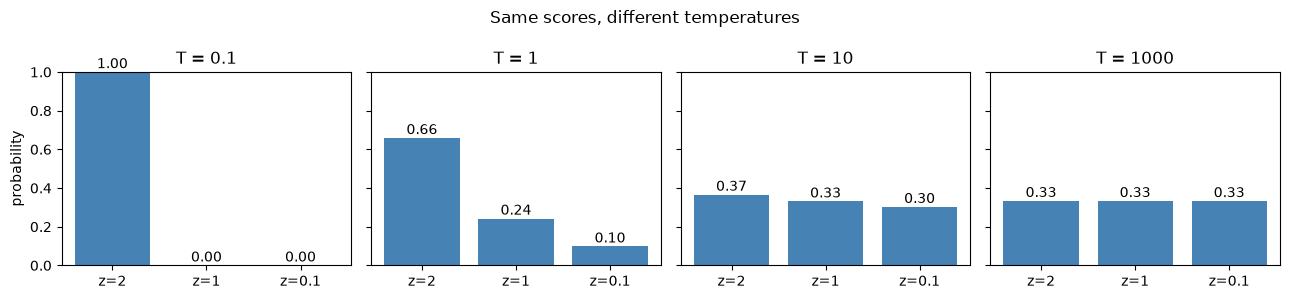

In [5]:
temps = [0.1, 1.0, 10.0, 1000.0]
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for ax, T in zip(axes, temps):
    pt = torch.softmax(z / T, dim=-1)
    ax.bar(["z=2", "z=1", "z=0.1"], pt, color="steelblue")
    ax.set_title(f"T = {T:g}")
    ax.set_ylim(0, 1)
    for i, v in enumerate(pt):
        ax.text(i, v.item() + 0.02, f"{v:.2f}", ha="center")
axes[0].set_ylabel("probability")
plt.suptitle("Same scores, different temperatures")
plt.tight_layout()
plt.show()

### 4. Shift invariance → numerical stability
Adding the same number to every score doesn't change the output. Softmax only looks at the gaps between scores. A quick check:

In [6]:
small = torch.tensor([1.0, 2.0, 3.0])
print("softmax([1, 2, 3])      :", torch.softmax(small, dim=-1).round(decimals=3))
print("softmax([101, 102, 103]):", torch.softmax(small + 100, dim=-1).round(decimals=3))

softmax([1, 2, 3])      : tensor([0.0900, 0.2450, 0.6650])
softmax([101, 102, 103]): tensor([0.0900, 0.2450, 0.6650])


Why? Subtracting a number c from every score multiplies every e^z by the same e^−c, on top and on the bottom, so it cancels.

This matters when scores are large. float32 can't hold e^x once x is above about 88, so it becomes `inf`. Here is the naive way, step by step:

In [7]:
big = torch.tensor([1000.0, 1001.0, 1002.0])
e = torch.exp(big)
print("scores:     ", big)
print("exp(scores):", e)
print("sum:        ", e.sum())
print("exp / sum:  ", e / e.sum())   # inf / inf = nan

scores:      tensor([1000., 1001., 1002.])
exp(scores): tensor([inf, inf, inf])
sum:         tensor(inf)
exp / sum:   tensor([nan, nan, nan])


Now subtract the max first. The largest score becomes 0, so every exp is at most 1 and nothing overflows. One term is exactly e^0 = 1, so the sum is at least 1 and we never divide by 0.

In [8]:
m = big.max()
shifted = big - m
e = torch.exp(shifted)
print("max:          ", m.item())
print("scores - max: ", shifted)
print("exp:          ", e.round(decimals=3))
print("sum:          ", round(e.sum().item(), 3))
print("exp / sum:    ", (e / e.sum()).round(decimals=3))
print("torch.softmax:", torch.softmax(big, dim=-1).round(decimals=3))   # torch subtracts the max internally

max:           1002.0
scores - max:  tensor([-2., -1.,  0.])
exp:           tensor([0.1350, 0.3680, 1.0000])
sum:           1.503
exp / sum:     tensor([0.0900, 0.2450, 0.6650])
torch.softmax: tensor([0.0900, 0.2450, 0.6650])


### 5. −∞ becomes exactly 0
Because e^−∞ = 0, setting a score to −∞ removes that option completely, and the remaining weights still sum to 1. This is how the causal mask in attention works.

In [9]:
masked = torch.tensor([2.0, 1.0, float("-inf")])
print("masked softmax:", torch.softmax(masked, dim=-1).round(decimals=3))

masked softmax: tensor([0.7310, 0.2690, 0.0000])


### 6. The weakness: big scores stop learning (why attention divides by √d_k)
Softmax works well when scores are small. When scores get big, the model stops learning. We'll see this in three steps.

**Step A: small vs. big scores.** Two scores. We nudge the second score up by 1 and check if the weights move.

In [10]:
nudge = torch.tensor([0.0, 1.0])
for scores in [[2.0, 1.0], [40.0, 20.0]]:
    s = torch.tensor(scores)
    before = torch.softmax(s, dim=-1)
    after = torch.softmax(s + nudge, dim=-1)
    print(f"scores {scores}:  weights {[round(x, 3) for x in before.tolist()]}  ->  after nudge {[round(x, 3) for x in after.tolist()]}")

scores [2.0, 1.0]:  weights [0.731, 0.269]  ->  after nudge [0.5, 0.5]
scores [40.0, 20.0]:  weights [1.0, 0.0]  ->  after nudge [1.0, 0.0]


- Small scores [2, 1]: the weights move. The model can tell which direction helps, so it can learn.
- Big scores [40, 20]: the first score already has all the weight (e^20 is about 500 million times bigger). The nudge changes nothing, so the model gets no signal and can't learn. Softmax has turned back into the Yes/No teacher from section 2.

**Step B: why scores get big.** A score is a dot product q·k, which adds up d_k numbers. Add up more numbers and you get bigger results. Here are 1000 random query-key pairs, for a few sizes of d_k:

In [11]:
_ = torch.manual_seed(1)
for d_k in [4, 64, 512]:
    Q = torch.randn(1000, d_k)
    K = torch.randn(1000, d_k)
    scores = (Q * K).sum(dim=-1)      # one dot product per pair
    print(f"d_k = {d_k:3d}  (√d_k = {math.sqrt(d_k):4.1f}):  scores spread (std) {scores.std():5.1f},  first 4 scores {[round(x, 1) for x in scores[:4].tolist()]}")

d_k =   4  (√d_k =  2.0):  scores spread (std)   2.0,  first 4 scores [-0.4, 0.1, 1.3, 0.0]
d_k =  64  (√d_k =  8.0):  scores spread (std)   7.8,  first 4 scores [4.2, 4.3, -5.4, 6.9]
d_k = 512  (√d_k = 22.6):  scores spread (std)  22.0,  first 4 scores [-30.0, -3.9, 40.7, 10.9]


The spread grows like √d_k: about 2, 8 and 23. With d_k = 512, scores are tens apart. That's the "big scores" case from Step A.

**Step C: the fix.** Divide the scores by √d_k. The spread goes back to about 1. Same query and keys (d_k = 512), before and after.

"Gradient size" below is how much the top weight reacts when we nudge the scores. Near 0 means the model can't learn.

In [12]:
_ = torch.manual_seed(0)
d_k, n = 512, 10
q = torch.randn(d_k)
K = torch.randn(n, d_k)
raw = K @ q
scaled = raw / math.sqrt(d_k)

for name, scores in [("raw q·k", raw), ("q·k / √d_k", scaled)]:
    s = scores.clone().requires_grad_()
    w = torch.softmax(s, dim=-1)
    w[w.argmax()].backward()          # how much the top weight reacts to the scores
    print(name)
    print("  scores spread (std):", round(scores.std().item(), 2))
    print("  weights:            ", [round(x, 2) for x in w.tolist()])
    print(f"  gradient size:       {s.grad.norm():.1e}")

raw q·k
  scores spread (std): 19.86
  weights:             [0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0]
  gradient size:       3.0e-11
q·k / √d_k
  scores spread (std): 0.88
  weights:             [0.02, 0.01, 0.09, 0.09, 0.12, 0.34, 0.1, 0.06, 0.09, 0.08]
  gradient size:       2.4e-01


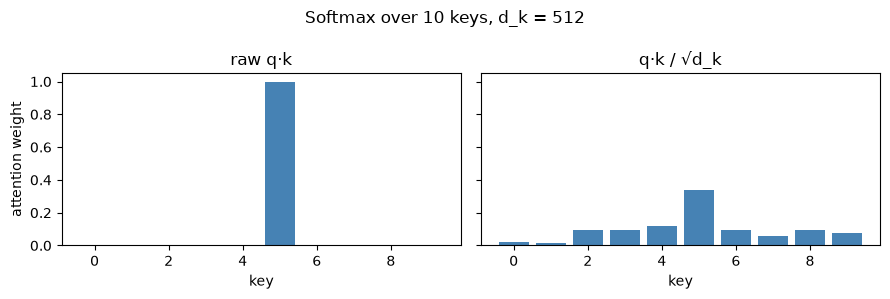

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for ax, (title, scores) in zip(axes, [("raw q·k", raw), ("q·k / √d_k", scaled)]):
    ax.bar(range(n), torch.softmax(scores, dim=-1), color="steelblue")
    ax.set_title(title)
    ax.set_xlabel("key")
axes[0].set_ylabel("attention weight")
plt.suptitle(f"Softmax over {n} keys, d_k = {d_k}")
plt.tight_layout()
plt.show()

- Raw: one key gets all the weight and the gradient is almost 0. No learning.
- Divided by √d_k: the weights are spread out and the gradient is healthy.

Dividing by √d_k is just temperature (section 3) with T = √d_k ≈ 22.6. This is the fix in the paper (Section 3.2.1, footnote 4).

## Summary
| Property | Where it shows up |
|---|---|
| Positive, sums to 1 | attention weights, class probabilities |
| Soft, differentiable argmax | anything trained with gradients |
| Temperature | LLM sampling |
| Shift invariance | numerically stable implementations |
| −∞ → 0 | causal and padding masks |
| Saturates on large inputs | the √d_k scaling in attention |